In [1]:
# Importing Libraries
import ast
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt 

# Loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

In [2]:
import seaborn as sns

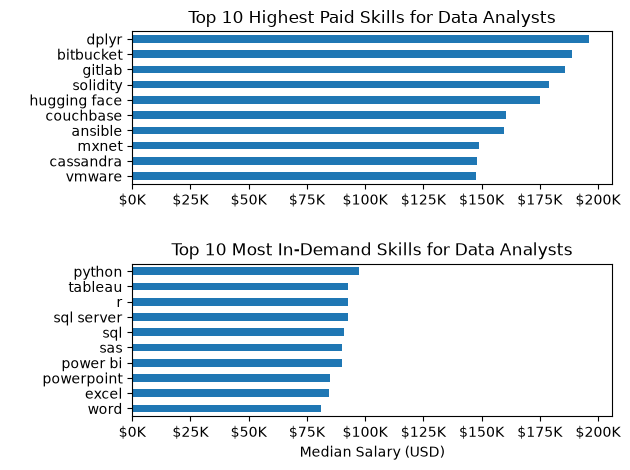

In [5]:
# Explode job_skills first so each row contains a single skill string
df_DA_US_exploded = df_DA_US.explode("job_skills")

# Now group by individual skill strings
df_DA_US_group = df_DA_US_exploded.groupby("job_skills")["salary_year_avg"].agg(["count", "median"])

df_DA_US_top_pay = df_DA_US_group.sort_values(by="median", ascending=False).head(10)

df_DA_US_skills = df_DA_US_group.sort_values(by="count", ascending=False).head(10).sort_values(by="median", ascending=False)

fig, ax = plt.subplots(2, 1) # 2 rows and 1 column

df_DA_US_top_pay.plot(kind="barh", y="median", ax=ax[0], legend=False)
ax[0].invert_yaxis()
ax[0].set_title("Top 10 Highest Paid Skills for Data Analysts")
ax[0].set_ylabel(" ")
ax[0].set_xlabel(" ")
ax[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${int(x/1000)}K'))

df_DA_US_skills.plot(kind="barh", y="median", ax=ax[1], legend=False)
ax[1].invert_yaxis()
ax[1].set_xlim(ax[0].get_xlim())
ax[1].set_title("Top 10 Most In-Demand Skills for Data Analysts")
ax[1].set_ylabel(" ")
ax[1].set_xlabel("Median Salary (USD)")
ax[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${int(x/1000)}K'))

fig.tight_layout()
plt.show()

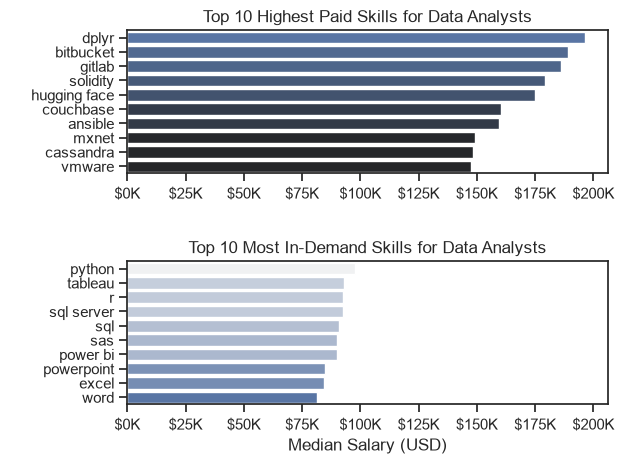

In [12]:
# Explode job_skills first so each row contains a single skill string
df_DA_US_exploded = df_DA_US.explode("job_skills")

# Now group by individual skill strings
df_DA_US_group = df_DA_US_exploded.groupby("job_skills")["salary_year_avg"].agg(["count", "median"])

df_DA_US_top_pay = df_DA_US_group.sort_values(by="median", ascending=False).head(10)

df_DA_US_skills = df_DA_US_group.sort_values(by="count", ascending=False).head(10).sort_values(by="median", ascending=False)

fig, ax = plt.subplots(2, 1) # 2 rows and 1 column

sns.set_theme(style="ticks")

sns.barplot(data=df_DA_US_top_pay, x="median", y=df_DA_US_top_pay.index, ax=ax[0], hue="median", palette="dark:b") # hue = what to color; b means blue;
ax[0].legend().remove()

#df_DA_US_top_pay.plot(kind="barh", y="median", ax=ax[0], legend=False)

ax[0].set_title("Top 10 Highest Paid Skills for Data Analysts")
ax[0].set_ylabel(" ")
ax[0].set_xlabel(" ")
ax[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${int(x/1000)}K'))

sns.barplot(data=df_DA_US_skills, x="median", y=df_DA_US_skills.index, ax=ax[1], hue="median", palette="light:b_r") # _r to reverse the gradient
ax[1].legend().remove()

#df_DA_US_skills.plot(kind="barh", y="median", ax=ax[1], legend=False)

ax[1].set_xlim(ax[0].get_xlim())
ax[1].set_title("Top 10 Most In-Demand Skills for Data Analysts")
ax[1].set_ylabel(" ")
ax[1].set_xlabel("Median Salary (USD)")
ax[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${int(x/1000)}K'))

fig.tight_layout()
plt.show()

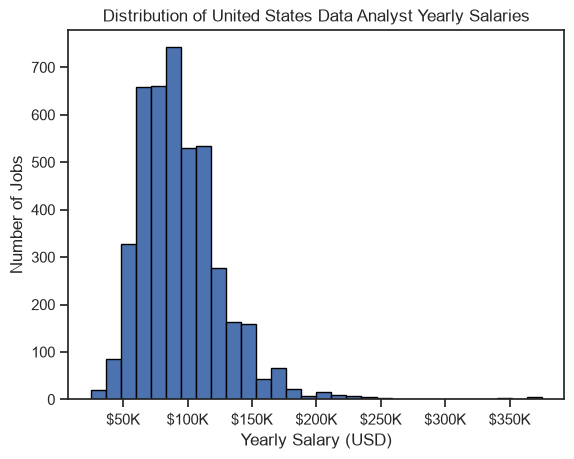

In [13]:
df_DA_US['salary_year_avg'].plot(kind='hist', bins=30, edgecolor='black')

plt.title('Distribution of United States Data Analyst Yearly Salaries')
plt.xlabel('Yearly Salary (USD)')
plt.ylabel('Number of Jobs')
ax = plt.gca()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda y, pos: f'${int(y/1000)}K'))
plt.show()

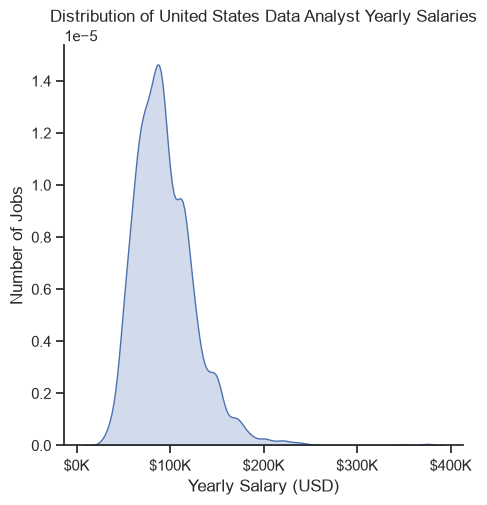

In [17]:
sns.displot(df_DA_US["salary_year_avg"], kind="kde", fill=True)

plt.title('Distribution of United States Data Analyst Yearly Salaries')
plt.xlabel('Yearly Salary (USD)')
plt.ylabel('Number of Jobs')
ax = plt.gca()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda y, pos: f'${int(y/1000)}K'))
plt.show()

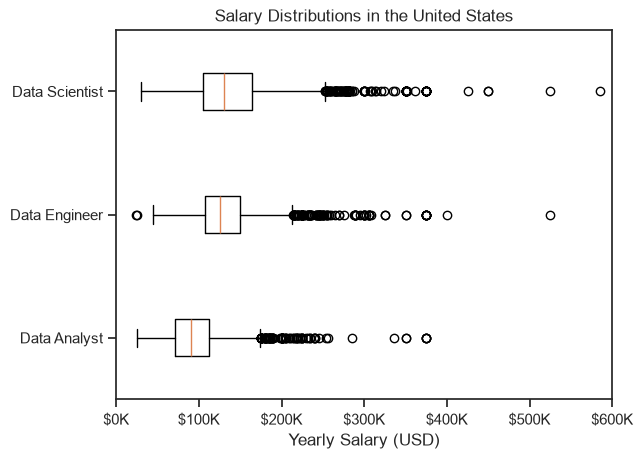

In [19]:
job_titles = ['Data Analyst', 'Data Engineer', 'Data Scientist']

# filter for the job titles and country
df_US = df[(df['job_title_short'].isin(job_titles)) & (df['job_country'] == 'United States')].dropna(subset=['salary_year_avg'])

# list of salaries for each job title
job_list = [df_US[df_US['job_title_short'] == job_title]['salary_year_avg'] for job_title in job_titles]

plt.boxplot(job_list, tick_labels=job_titles, orientation='horizontal')
plt.title('Salary Distributions in the United States')
plt.xlabel('Yearly Salary (USD)')
plt.xlim(0, 600000) 
ticks_x = plt.FuncFormatter(lambda y, pos: f'${int(y/1000)}K')
plt.gca().xaxis.set_major_formatter(ticks_x)
plt.show()

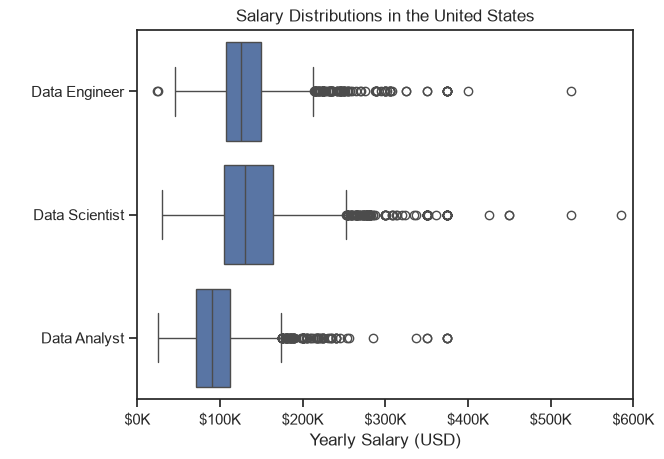

In [21]:
sns.boxplot(data=df_US, x="salary_year_avg", y="job_title_short")

plt.title('Salary Distributions in the United States')
plt.xlabel('Yearly Salary (USD)')
plt.ylabel(' ')
plt.xlim(0, 600000) 
ticks_x = plt.FuncFormatter(lambda y, pos: f'${int(y/1000)}K')
plt.gca().xaxis.set_major_formatter(ticks_x)
plt.show()